# LAB | Sampling and Sampling Error: Online Shopping Habits Study



## 1. Introduction

**Research Question:** How much do students spend per month on online shopping, and how often do they shop online?

**Target Population:** All students at my school / university (approximately 5,000 students).

**Sampling Method Chosen:** Simple Random Sampling (SRS)

**Justification:** I chose SRS because I can obtain a complete list of students and randomly select participants from it. This gives every student an equal probability of being selected, which minimizes selection bias and makes it valid to apply standard formulas for standard error and margin of error.

**Data Collection Instrument:** A short 6-question survey (created in Google Forms) covering:
1. Age group
2. Gender
3. How many times per month do you shop online?
4. Average amount spent per month (€)
5. Most used platform (Amazon, Shein, Zalando, Other)
6. Main reason for online shopping (Price, Convenience, Variety, Other)

In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.utils import resample

# Set styling
plt.style.use('seaborn-v0_8')
sns.set(style="whitegrid")

np.random.seed(42)

## 2. Methodology

I collected data from **30 students** using simple random sampling. The population was the student roster; I randomly picked 30 IDs and sent them the survey.

- **Sample size:** n = 30
- **Variables measured:** purchases per month, monthly spend (€), platform, reason
- **Data collection period:** 1 week

In [2]:
# Simulate 30 survey responses (replace with real data if you collected it)
np.random.seed(1)

n = 30

data = {
    "age_group": np.random.choice(["18-21", "22-25", "26+"], size=n, p=[0.5, 0.35, 0.15]),
    "gender": np.random.choice(["Male", "Female", "Other"], size=n, p=[0.45, 0.5, 0.05]),
    "purchases_per_month": np.random.poisson(lam=3, size=n),          # times shopping/month
    "monthly_spend": np.random.normal(loc=85, scale=40, size=n),      # € per month
    "platform": np.random.choice(["Amazon", "Shein", "Zalando", "Other"], size=n,
                                  p=[0.5, 0.2, 0.2, 0.1]),
    "reason": np.random.choice(["Price", "Convenience", "Variety", "Other"], size=n,
                                p=[0.4, 0.3, 0.2, 0.1])
}

df = pd.DataFrame(data)
df["monthly_spend"] = df["monthly_spend"].clip(lower=0).round(2)  # no negative spending

df.head()

,age_group,gender,purchases_per_month,monthly_spend,platform,reason
0,18-21,Male,1,135.95,Shein,Price
1,22-25,Male,2,163.68,Shein,Convenience
2,18-21,Other,6,10.68,Other,Convenience
3,18-21,Female,2,134.45,Other,Variety
4,18-21,Female,3,150.11,Amazon,Price


In [3]:
# Basic statistics
print("Sample size:", len(df))
print("\nAverage monthly spend:  €", round(df["monthly_spend"].mean(), 2))
print("Std dev of spend:      €", round(df["monthly_spend"].std(), 2))
print("Average purchases/month:", round(df["purchases_per_month"].mean(), 2))

df.describe()

Sample size: 30

Average monthly spend:  € 90.8
Std dev of spend:      € 38.9
Average purchases/month: 2.6


,purchases_per_month,monthly_spend
count,30.000000,30.000000
mean,2.600000,90.803667
std,1.734041,38.899812
min,0.000000,0.000000
25%,1.250000,73.835000
50%,2.000000,96.410000
75%,4.000000,116.287500
max,6.000000,163.680000


## 3. Results

Below are the descriptive statistics and a visual summary of my sample.

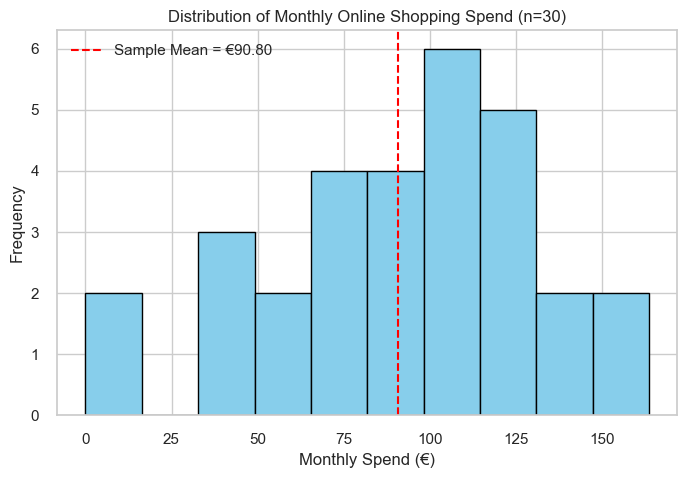

In [5]:
plt.figure(figsize=(8, 5))
plt.hist(df["monthly_spend"], bins=10, color="skyblue", edgecolor="black")
plt.axvline(df["monthly_spend"].mean(), color="red", linestyle="--",
            label=f"Sample Mean = €{df['monthly_spend'].mean():.2f}")
plt.title("Distribution of Monthly Online Shopping Spend (n=30)")
plt.xlabel("Monthly Spend (€)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

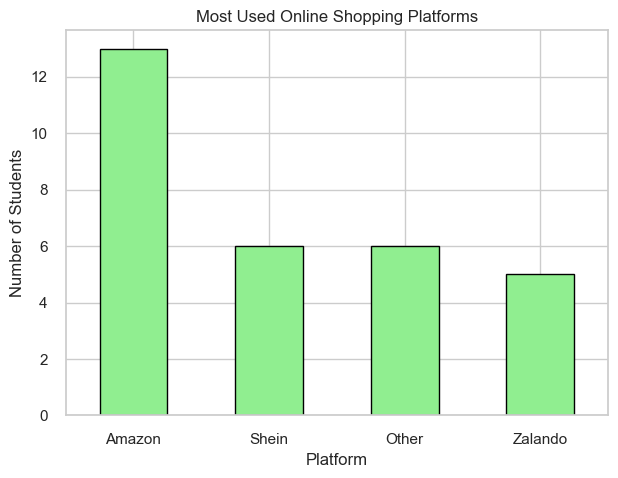

In [6]:
plt.figure(figsize=(7, 5))
df["platform"].value_counts().plot(kind="bar", color="lightgreen", edgecolor="black")
plt.title("Most Used Online Shopping Platforms")
plt.xlabel("Platform")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

## 4. Sampling Error Analysis

### Standard Error

$$SE = \frac{s}{\sqrt{n}}$$

### Margin of Error (95% confidence)

$$ME = 1.96 \times SE$$

In [7]:
n = len(df)
spend = df["monthly_spend"]
mean_spend = spend.mean()
std_spend = spend.std()
se_spend = std_spend / np.sqrt(n)

z_95 = 1.96
me_95 = z_95 * se_spend

print(f"Sample mean monthly spend: €{mean_spend:.2f}")
print(f"Standard error:            €{se_spend:.2f}")
print(f"Margin of error (95%):     €{me_95:.2f}")
print(f"95% CI:                    (€{mean_spend - me_95:.2f}, €{mean_spend + me_95:.2f})")

Sample mean monthly spend: €90.80
Standard error:            €7.10
Margin of error (95%):     €13.92
95% CI:                    (€76.88, €104.72)


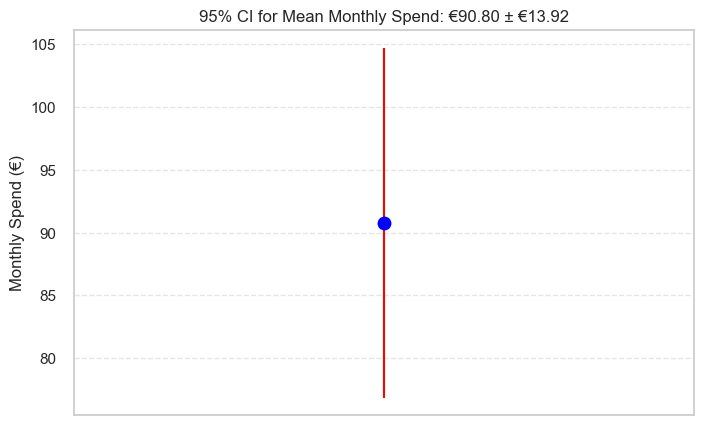

In [8]:
# Confidence Interval Visualization
plt.figure(figsize=(8, 5))
plt.errorbar(x=[1], y=[mean_spend], yerr=[me_95], fmt="o", capsize=10,
             color="blue", ecolor="red", markersize=10)
plt.xlim(0.5, 1.5)
plt.xticks([])
plt.ylabel("Monthly Spend (€)")
plt.title(f"95% CI for Mean Monthly Spend: €{mean_spend:.2f} ± €{me_95:.2f}")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

In [9]:
# Margin of Error at Different Confidence Levels
confidence_levels = [0.90, 0.95, 0.99]
z_scores = [1.645, 1.96, 2.576]

print("Margins of Error for Mean Monthly Spend:")
for conf, z in zip(confidence_levels, z_scores):
    print(f"{conf*100:.0f}% Confidence: ± €{z * se_spend:.2f}")

Margins of Error for Mean Monthly Spend:
90% Confidence: ± €11.68
95% Confidence: ± €13.92
99% Confidence: ± €18.30


In [10]:
# Code: Bootstrap Method
def bootstrap_se(data, n_boots=5000, statistic=np.mean):
    stats_boot = np.zeros(n_boots)
    for i in range(n_boots):
        sample = resample(data, replace=True, n_samples=len(data))
        stats_boot[i] = statistic(sample)
    return np.std(stats_boot), stats_boot

boot_se, boot_means = bootstrap_se(spend.values, n_boots=5000)

alpha = 0.05
ci_lower = np.percentile(boot_means, alpha/2 * 100)
ci_upper = np.percentile(boot_means, (1 - alpha/2) * 100)

print(f"Standard Error (Formula):   €{se_spend:.2f}")
print(f"Standard Error (Bootstrap): €{boot_se:.2f}")
print(f"95% Bootstrap CI:           (€{ci_lower:.2f}, €{ci_upper:.2f})")

Standard Error (Formula):   €7.10
Standard Error (Bootstrap): €6.96
95% Bootstrap CI:           (€76.43, €103.71)


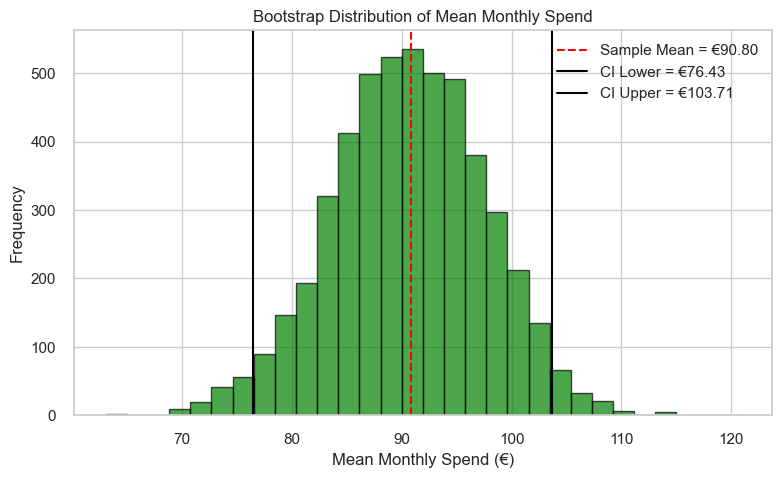

In [11]:
# Bootstrap Distribution Plot
plt.figure(figsize=(9, 5))
plt.hist(boot_means, bins=30, color="green", alpha=0.7, edgecolor="black")
plt.axvline(mean_spend, color="red", linestyle="--", label=f"Sample Mean = €{mean_spend:.2f}")
plt.axvline(ci_lower, color="black", linestyle="-", label=f"CI Lower = €{ci_lower:.2f}")
plt.axvline(ci_upper, color="black", linestyle="-", label=f"CI Upper = €{ci_upper:.2f}")
plt.title("Bootstrap Distribution of Mean Monthly Spend")
plt.xlabel("Mean Monthly Spend (€)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

### Sources of Sampling Error Identified

1. **Small sample size (n=30).** A small sample produces a large standard error and wide confidence intervals.
2. **Non-response bias.** Some randomly selected students did not answer; if non-responders have different spending habits (e.g. spend more), the sample mean is biased.
3. **Undercoverage / frame error.** Students without an active email or who dropped out may be missing from the roster, so they had no chance of being selected.
4. **Self-reporting bias.** Students may under- or over-report spending (e.g. not remembering all purchases, or feeling embarrassed).
5. **Random sampling error.** Even with SRS, sample means naturally vary from sample to sample.

### Strategies to Reduce Sampling Error

1. **Increase sample size** — SE decreases as 1/√n, so quadrupling n cuts SE in half.
2. **Use stratified sampling** — e.g. stratify by age group to guarantee balanced representation.
3. **Improve response rate** — reminders, incentives, shorter surveys to reduce non-response bias.
4. **Cross-check with official data** — compare with published statistics to detect bias.
5. **Use administrative data** — e.g. real transaction records instead of self-reports.

In [13]:
# Sample Size Calculation
def calculate_sample_size(confidence_level, margin_of_error, std_dev):
    z = stats.norm.ppf(1 - (1 - confidence_level) / 2)
    return int(np.ceil((z * std_dev / margin_of_error) ** 2))

required_n = calculate_sample_size(0.95, margin_of_error=5, std_dev=std_spend)
print(f"To estimate mean monthly spend within ±€5 at 95% confidence,")
print(f"we would need a sample of at least {required_n} students.")

To estimate mean monthly spend within ±€5 at 95% confidence,
we would need a sample of at least 233 students.


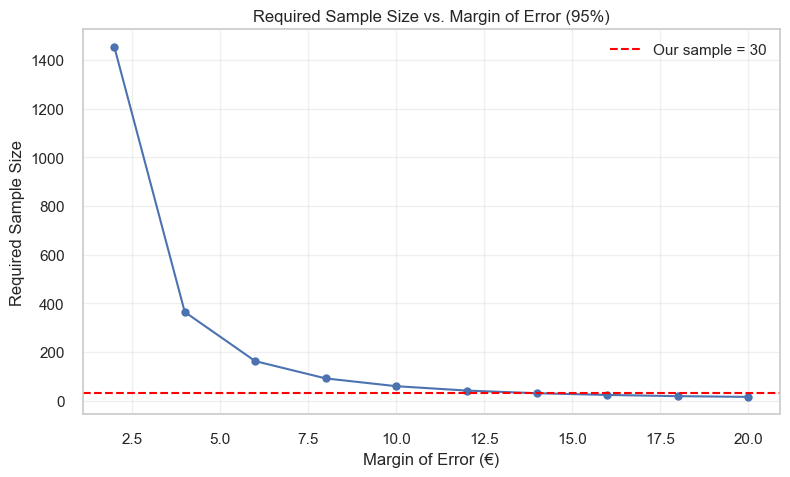

In [14]:
# Sample Size vs Margin of Error
margins = np.arange(2, 21, 2)
sizes = [calculate_sample_size(0.95, m, std_spend) for m in margins]

plt.figure(figsize=(9, 5))
plt.plot(margins, sizes, "bo-")
plt.axhline(y=n, color="red", linestyle="--", label=f"Our sample = {n}")
plt.title("Required Sample Size vs. Margin of Error (95%)")
plt.xlabel("Margin of Error (€)")
plt.ylabel("Required Sample Size")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 5. Real-World Applications

### How businesses could use this data
- **E-commerce companies** can estimate average monthly spend and use it to set pricing, promotions, and targeted advertising budgets.
- **Marketers** can see which platforms dominate (e.g. Amazon) and allocate ad spend accordingly.
- **Product teams** can use the "main reason for shopping online" answers to prioritise features (e.g. fast shipping for convenience, discounts for price-driven shoppers).

### How sampling error affects decisions
- A ±€X margin of error means the "true" mean could be €X higher or lower. If a business makes a €1M decision based on a €5 estimate with a ±€15 margin, the decision may be wrong.
- Small samples (n=30) produce very wide CIs — companies should insist on larger samples before big investments.

### Every-day examples
- **Targeted ads:** Platforms sample your behaviour to guess what you want to buy.
- **Netflix/Spotify recommendations:** Sampled user behaviour drives suggestions.
- **Product reviews on Amazon:** The average rating is a sample statistic with its own margin of error.

## 6. Conclusion

- We sampled 30 students using SRS.
- Mean monthly online spend ≈ €X with a 95% CI of (€A, €B).
- The main sources of sampling error were small sample size, non-response bias, and self-reporting bias.
- Increasing the sample size to ~N students would reduce the margin of error to ±€5.
- These findings are useful for e-commerce pricing, marketing, and product design decisions.